In [82]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')


In [ ]:
df= pd.read_csv("insurance.csv")
print(df.head())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


: 

: 

: 

EDA

In [ ]:
df.shape



(1338, 7)

: 

: 

: 

In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


: 

: 

: 

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


: 

: 

: 

In [ ]:
df.describe(include='all')

,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


: 

: 

: 

In [ ]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

: 

: 

: 

In [ ]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

: 

: 

: 

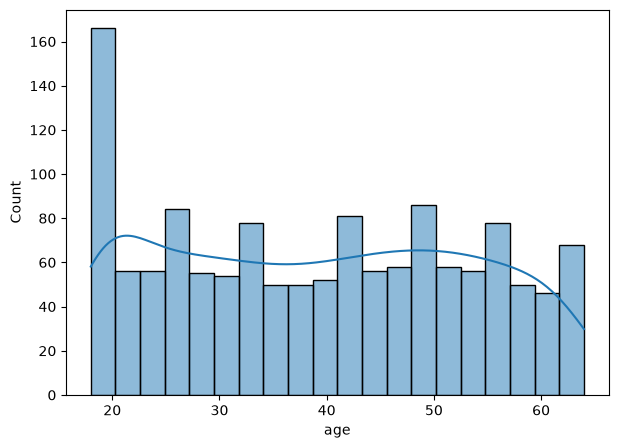

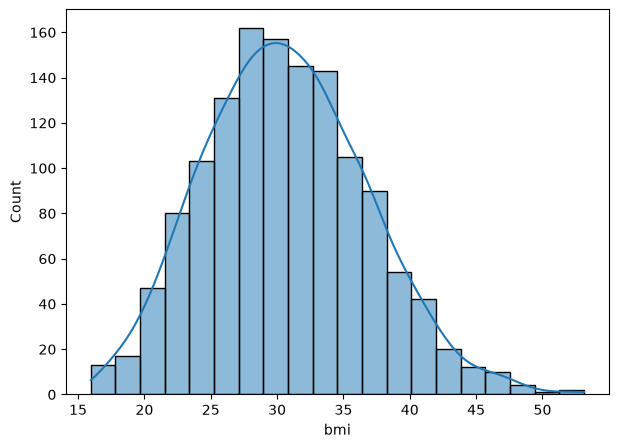

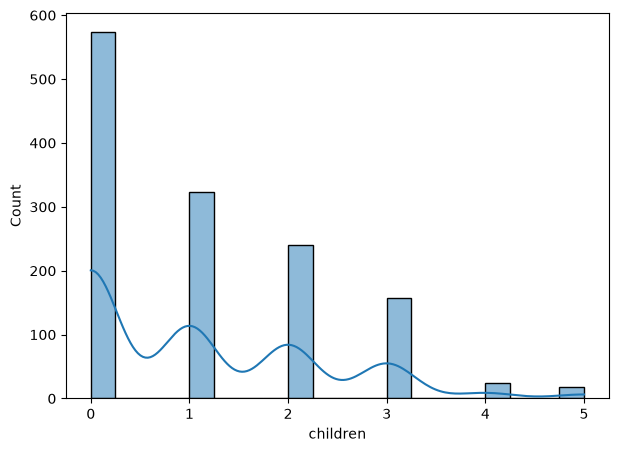

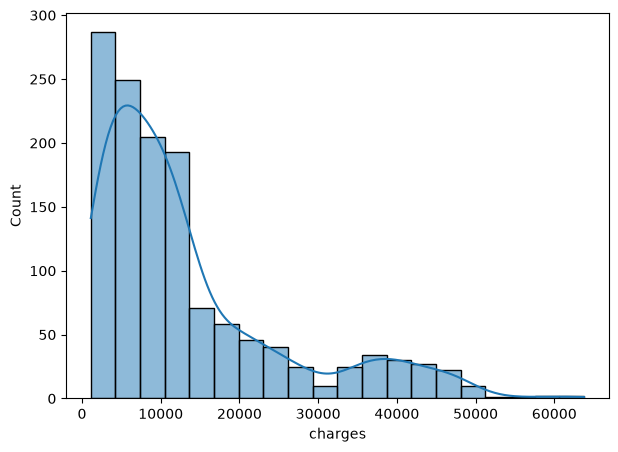

: 

: 

: 

In [ ]:
numeric_column=['age','bmi','children','charges']
for col in numeric_column:
    plt.figure(figsize=(7,5))
    sns.histplot(df[col],kde= True,bins=20)



<Axes: xlabel='children', ylabel='count'>

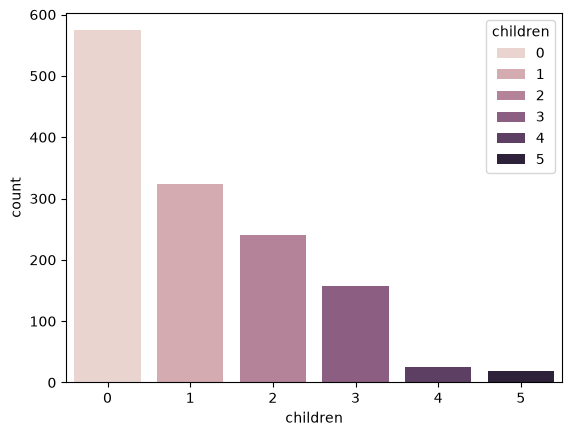

: 

: 

: 

In [ ]:
sns.countplot(x=df['children'],hue=df['children'])

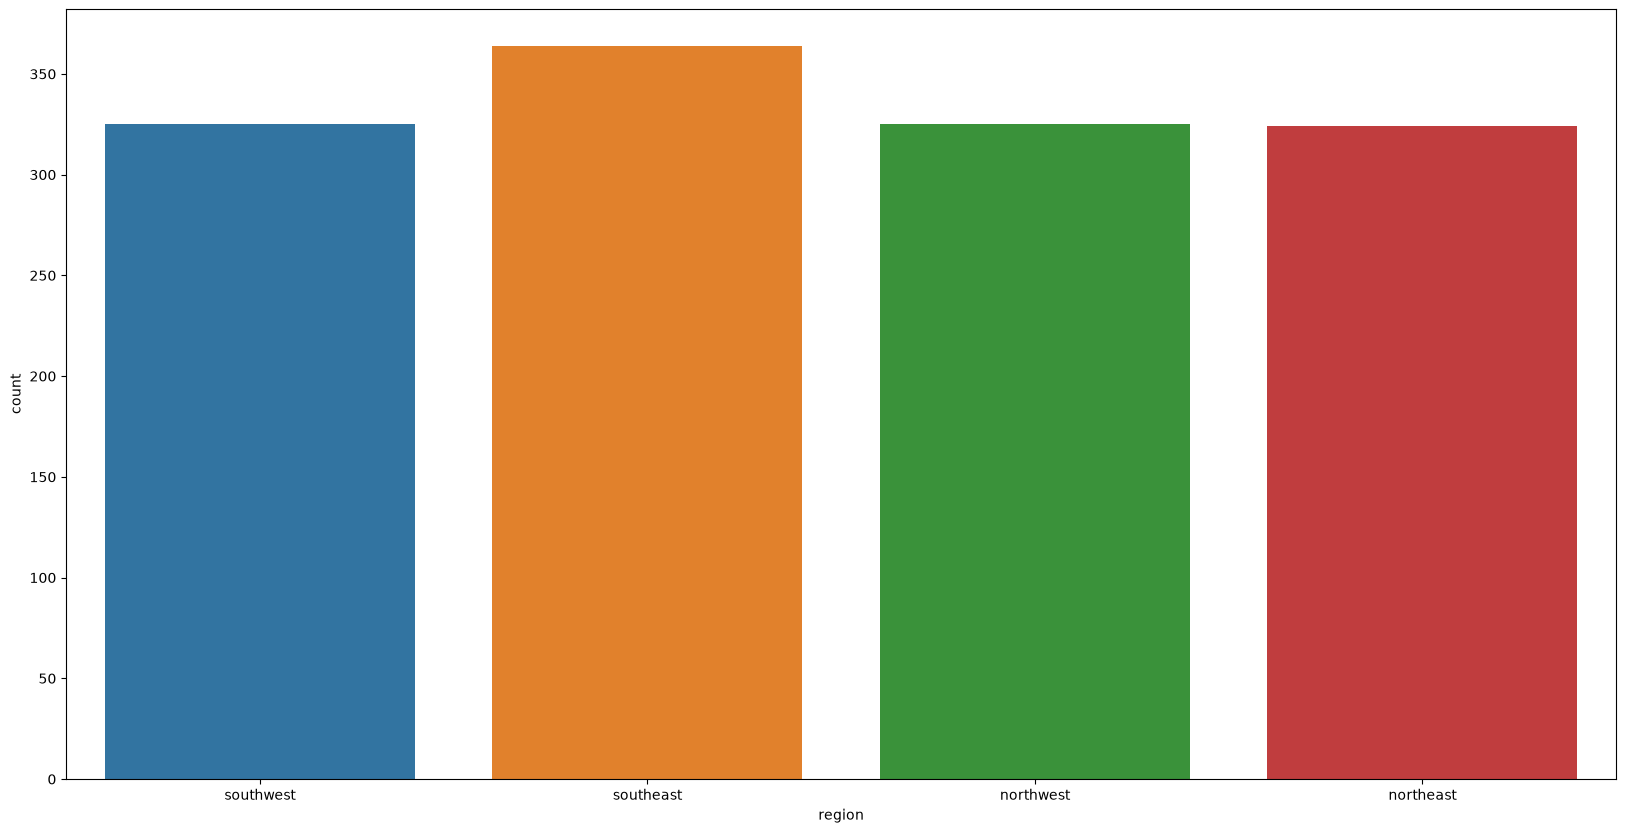

: 

: 

: 

In [ ]:
plt.figure(figsize=(20,10))
sns.countplot(x=df['region'],hue=df['region'])
plt.show()

<Axes: xlabel='sex', ylabel='count'>

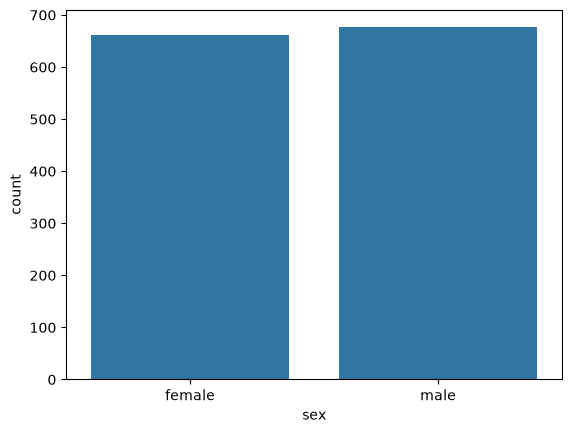

: 

: 

: 

In [ ]:
sns.countplot(x=df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

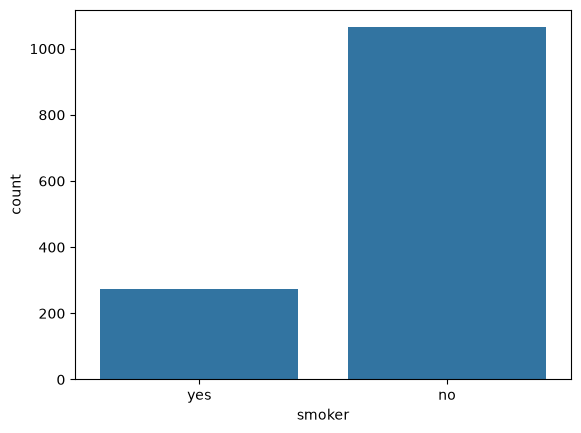

: 

: 

: 

In [ ]:
sns.countplot(x=df['smoker'])

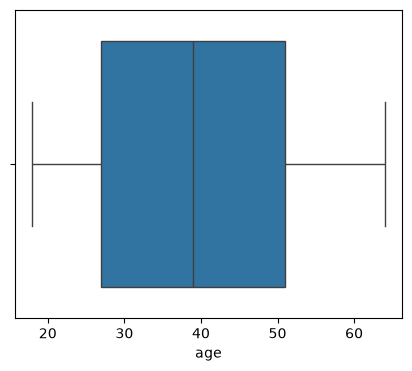

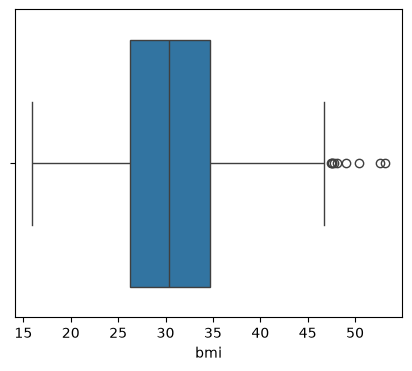

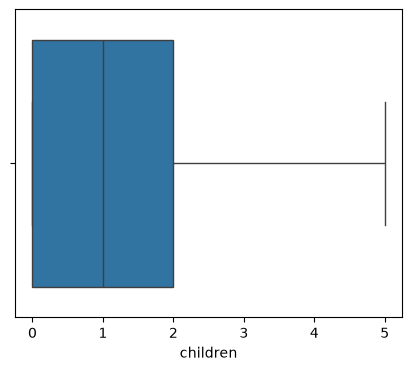

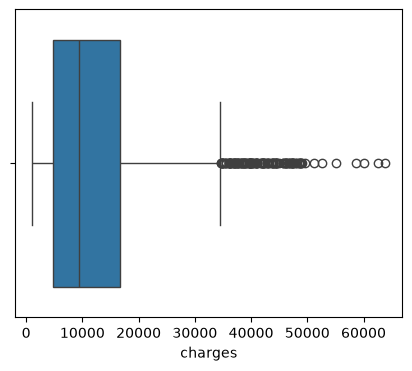

: 

: 

: 

In [ ]:
for col in numeric_column:
    plt.figure(figsize=(5,4))
    sns.boxplot(x=df[col])


<Axes: >

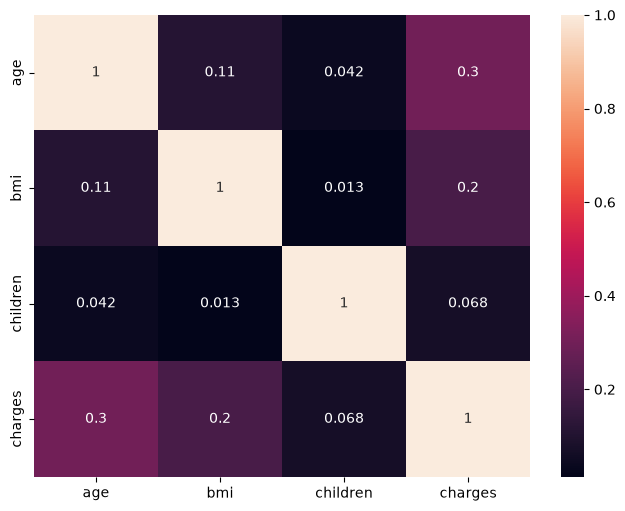

: 

: 

: 

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)


# Data cleaning and preproccesing

In [ ]:
data_cleaned= df.copy()
data_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

: 

: 

: 

In [ ]:
data_cleaned.duplicated().sum()

np.int64(1)

: 

: 

: 

In [ ]:
data_cleaned.drop_duplicates(inplace=True)

: 

: 

: 

In [ ]:
data_cleaned.duplicated().sum()

np.int64(0)

: 

: 

: 

In [ ]:
data_cleaned.dtypes


age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

: 

: 

: 

In [ ]:
data_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

: 

: 

: 

In [ ]:
data_cleaned['sex']=data_cleaned['sex'].map({'male':0,'female':1})


: 

: 

: 

In [ ]:
data_cleaned['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

: 

: 

: 

In [ ]:
data_cleaned['smoker']=data_cleaned['smoker'].map(
    {
    'no':0,
    'yes':1}
    )

: 

: 

: 

In [ ]:
data_cleaned.rename(columns={
    'sex':'is_female',
    'smoker':'is_smoker'
},inplace=True)

: 

: 

: 

In [ ]:
data_cleaned.head(3)

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.90,0,1,southwest,16884.9240
1,18,0,33.77,1,0,southeast,1725.5523
2,28,0,33.00,3,0,southeast,4449.4620


: 

: 

: 

In [ ]:
data_cleaned['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

: 

: 

: 

In [ ]:

data_cleaned= pd.get_dummies(data_cleaned,columns=['region'],drop_first=False)


: 

: 

: 

In [ ]:
data_cleaned=data_cleaned.astype(int)

: 

: 

: 

In [ ]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,0,1
1,18,0,33,1,0,1725,0,0,1,0
2,28,0,33,3,0,4449,0,0,1,0
3,33,0,22,0,0,21984,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0


: 

: 

: 

# Feature Engineering and Extraction

In [ ]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,0,1
1,18,0,33,1,0,1725,0,0,1,0
2,28,0,33,3,0,4449,0,0,1,0
3,33,0,22,0,0,21984,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0


: 

: 

: 

In [ ]:
data_cleaned['age_category']=pd.cut(data_cleaned['age'],
        bins=[0,14,25,45,60,75,float('inf')],
        labels=['children','youth','adult','middle age','elder','senior']
    )

: 

: 

: 

In [ ]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,age_category
0,19,1,27,0,1,16884,0,0,0,1,youth
1,18,0,33,1,0,1725,0,0,1,0,youth
2,28,0,33,3,0,4449,0,0,1,0,adult
3,33,0,22,0,0,21984,0,1,0,0,adult
4,32,0,28,0,0,3866,0,1,0,0,adult


: 

: 

: 

In [ ]:
data_cleaned['age_category'].value_counts()

age_category
adult         532
middle age    409
youth         305
elder          91
children        0
senior          0
Name: count, dtype: int64

: 

: 

: 

In [ ]:
data_cleaned =pd.get_dummies(data_cleaned,columns=['age_category'],drop_first=False)


: 

: 

: 

In [ ]:
data_cleaned=data_cleaned.astype(int)

: 

: 

: 

In [ ]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,age_category_children,age_category_youth,age_category_adult,age_category_middle age,age_category_elder,age_category_senior
0,19,1,27,0,1,16884,0,0,0,1,0,1,0,0,0,0
1,18,0,33,1,0,1725,0,0,1,0,0,1,0,0,0,0
2,28,0,33,3,0,4449,0,0,1,0,0,0,1,0,0,0
3,33,0,22,0,0,21984,0,1,0,0,0,0,1,0,0,0
4,32,0,28,0,0,3866,0,1,0,0,0,0,1,0,0,0


: 

: 

: 

In [ ]:
# feature scaling

from sklearn.preprocessing import StandardScaler
col=['age','bmi','children']
scaler= StandardScaler()

data_cleaned[col]= scaler.fit_transform(data_cleaned[col])

ModuleNotFoundError: No module named 'sklearn'

: 

: 

: 

In [ ]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,age_category_children,age_category_youth,age_category_adult,age_category_middle age,age_category_elder,age_category_senior
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,0,1,0,0,0,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,0,1,0,0,0,0
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,0,0,1,0,0,0
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,0,0,1,0,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,0,0,1,0,0,0


: 

: 

: 

In [ ]:
data_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'age_category_children', 'age_category_youth',
       'age_category_adult', 'age_category_middle age', 'age_category_elder',
       'age_category_senior'],
      dtype='str')

: 

: 

: 

In [ ]:
from scipy.stats import pearsonr

selected_features=['age', 'is_female', 'bmi', 'children', 'is_smoker',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'age_category_children', 'age_category_youth',
       'age_category_adult', 'age_category_middle age', 'age_category_elder',
       'age_category_senior']

correlation = {
    feature: pearsonr(data_cleaned[feature],data_cleaned['charges'])[0]
    for feature in selected_features
}

correlation_data_cleaned = pd.DataFrame(correlation.items(),columns=['features','correlation'])
correlation_data_cleaned= correlation_data_cleaned.sort_values(by="correlation",ascending=False)

correlation_data_cleaned

,features,correlation
4,is_smoker,0.787234
0,age,0.298309
2,bmi,0.196236
13,age_category_elder,0.173769
12,age_category_middle age,0.167911
7,region_southeast,0.073577
3,children,0.067390
5,region_northeast,0.005946
6,region_northwest,-0.038695
8,region_southwest,-0.043637


: 

: 

: 

In [ ]:
cat_features= [ 'is_female', 'is_smoker',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'age_category_children', 'age_category_youth',
       'age_category_adult', 'age_category_middle age', 'age_category_elder',
       'age_category_senior']

from scipy.stats import chi2_contingency

alpha= 0.05
data_cleaned['charges_category'] = pd.cut(
    data_cleaned['charges'],
    bins=4,
    labels=False)
results=[]
for feature in cat_features:
    contingency_table = pd.crosstab(data_cleaned[feature], data_cleaned['charges_category'])

    chi2, p_value, _, _= chi2_contingency(contingency_table)


    if p_value < alpha:
        comment="Comment: KEEP - Significant association with charges."
    else:
        comment="Comment: REMOVE - No significant association with charges."

    results.append({
    'features': feature,
    'chi_square':chi2,
    'p_value':p_value,
    'comment':comment
    })
    chi_square_data_cleaned= pd.DataFrame(results)
chi_square_data_cleaned



,features,chi_square,p_value,comment
0,is_female,11.212656,1.062983e-02,Comment: KEEP - Significant association with c...
1,is_smoker,918.577819,8.266679e-199,Comment: KEEP - Significant association with c...
2,region_northeast,2.395273,4.945152e-01,Comment: REMOVE - No significant association w...
3,region_northwest,5.611610,1.321134e-01,Comment: REMOVE - No significant association w...
4,region_southeast,13.502398,3.667019e-03,Comment: KEEP - Significant association with c...
5,region_southwest,6.611919,8.535165e-02,Comment: REMOVE - No significant association w...
6,age_category_children,0.000000,1.000000e+00,Comment: REMOVE - No significant association w...
7,age_category_youth,9.409282,2.431629e-02,Comment: KEEP - Significant association with c...
8,age_category_adult,0.538035,9.104592e-01,Comment: REMOVE - No significant association w...
9,age_category_middle age,5.662094,1.292587e-01,Comment: REMOVE - No significant association w...


: 

: 

: 

In [ ]:
final_cleaned_df=data_cleaned[['age', 'is_female', 'bmi', 'children', 'is_smoker',
'charges', 'region_southeast','age_category_youth','charges_category']]

final_cleaned_df

,age,is_female,bmi,children,is_smoker,charges,region_southeast,age_category_youth,charges_category
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,1,1
1,-1.511647,0,0.462463,-0.079442,0,1725,1,1,0
2,-0.799350,0,0.462463,1.580143,0,4449,1,0,0
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,0,1
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,0,0
...,...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,0,0
1334,-1.511647,1,0.135659,-0.909234,0,2205,0,1,0
1335,-1.511647,1,0.952670,-0.909234,0,1629,1,1,0
1336,-1.297958,1,-0.844753,-0.909234,0,2007,0,1,0


: 

: 

: 

: 

: 

: 